In [2]:
import pandas as pd
from pathlib import Path

# Find the dataset
paths = [
    Path("data/raw/ai4i2020.csv"),
    Path("/home/ga3riel/machineguard-ml/raw/ai4i+2020+predictive+maintenance+dataset/ai4i2020.csv")
]

data_path = next(
    (path for path in paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Dataset CSV not found")

# Load the dataset
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [7]:
df["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [8]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

Matplotlib is building the font cache; this may take a moment.


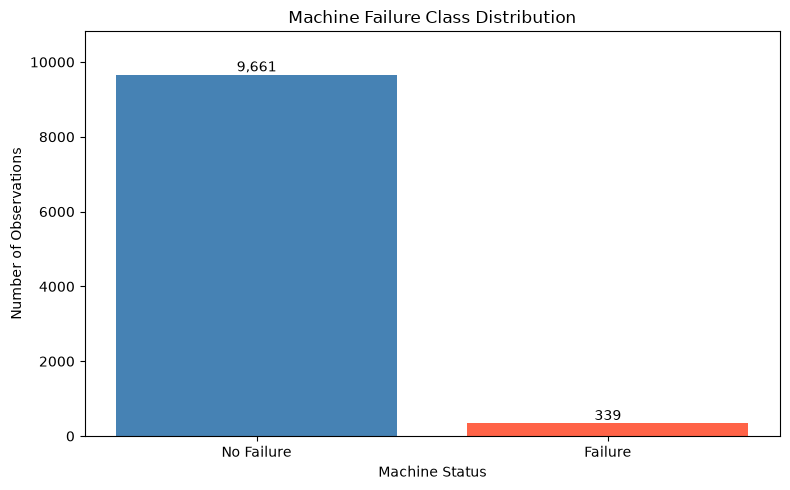

In [9]:
import matplotlib.pyplot as plt

# Count observations in each class
class_counts = (
    df["Machine failure"]
    .value_counts()
    .sort_index()
)

# Create the chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["No Failure", "Failure"],
    class_counts.values,
    color=["steelblue", "tomato"]
)

# Labels and title
ax.set_title("Machine Failure Class Distribution")
ax.set_xlabel("Machine Status")
ax.set_ylabel("Number of Observations")

# Show counts above bars
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, class_counts.max() * 1.12)

plt.tight_layout()
plt.show()

## Feature Analysis — Normal vs Failure Conditions

In [10]:
features = [
    "Torque [Nm]",
    "Rotational speed [rpm]",
    "Tool wear [min]"
]

df.groupby("Machine failure")[features].median()

,Torque [Nm],Rotational speed [rpm],Tool wear [min]
Machine failure,,,
0,39.9,1507.0,107.0
1,53.7,1365.0,165.0


## Box Plot Analysis of Machine Operating Conditions

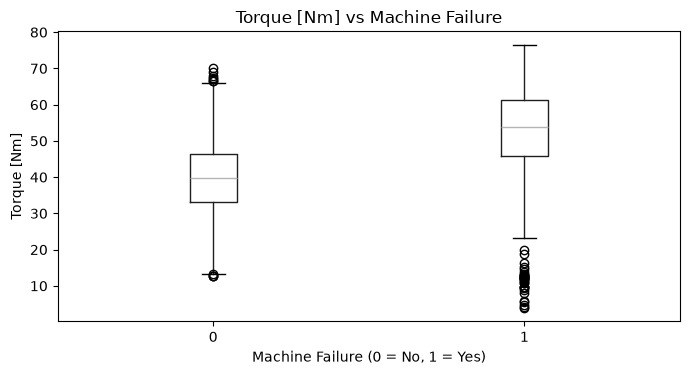

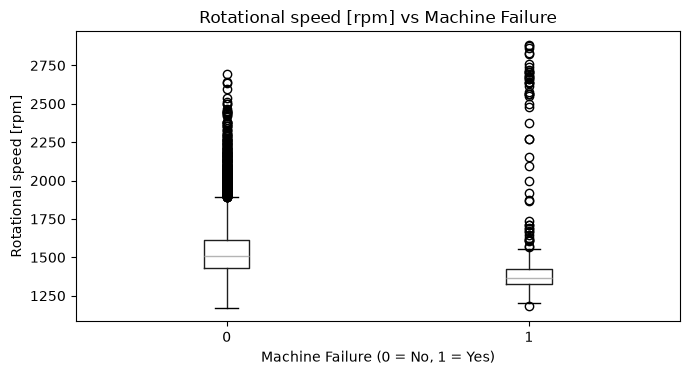

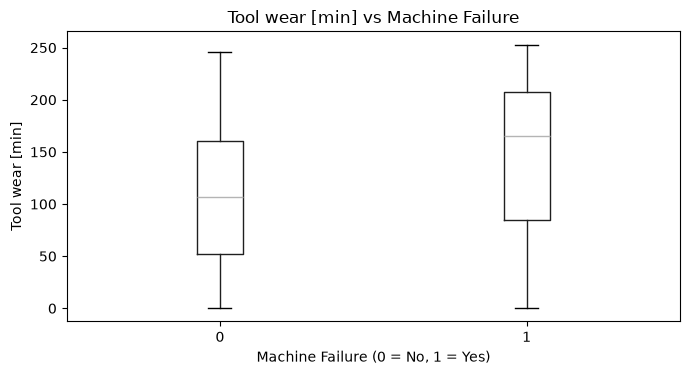

In [11]:
for feature in features:

    fig, ax = plt.subplots(figsize=(7, 4))

    df.boxplot(
        column=feature,
        by="Machine failure",
        ax=ax,
        grid=False
    )

    ax.set_title(f"{feature} vs Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

    plt.suptitle("")
    plt.tight_layout()
    plt.show()

## Relationship Between Torque, Rotational Speed and Machine Failure

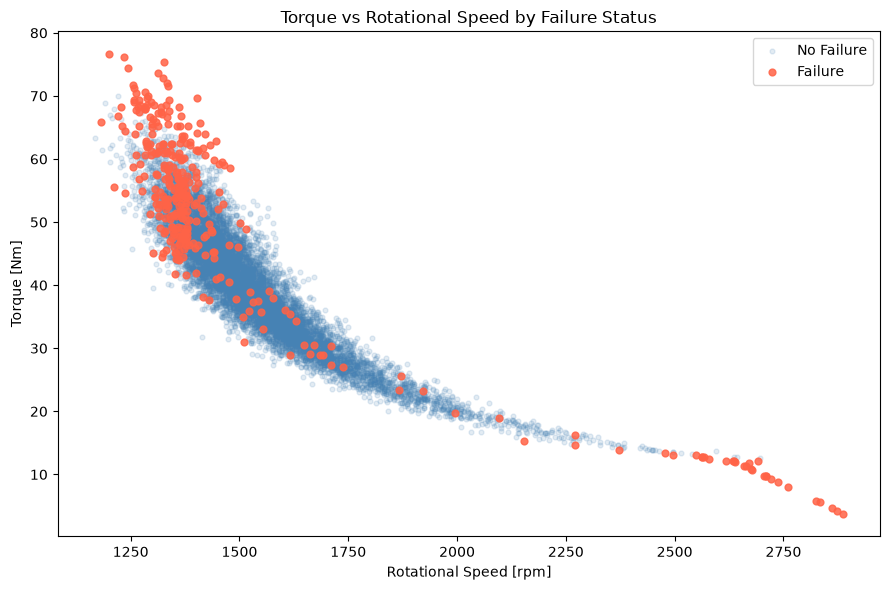

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))

# Plot normal observations first
normal = df[df["Machine failure"] == 0]

ax.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.15,
    s=12,
    color="steelblue",
    label="No Failure"
)

# Plot failure observations on top
failed = df[df["Machine failure"] == 1]

ax.scatter(
    failed["Rotational speed [rpm]"],
    failed["Torque [Nm]"],
    alpha=0.85,
    s=24,
    color="tomato",
    label="Failure"
)

ax.set_title("Torque vs Rotational Speed by Failure Status")
ax.set_xlabel("Rotational Speed [rpm]")
ax.set_ylabel("Torque [Nm]")
ax.legend()

plt.tight_layout()
plt.show()

## Correlation Analysis

In [13]:
# Select the two features
selected_features = [
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

# Calculate Pearson correlation
correlation = df[selected_features].corr()

display(correlation)

,Rotational speed [rpm],Torque [Nm]
Rotational speed [rpm],1.000000,-0.875027
Torque [Nm],-0.875027,1.000000


## Failure Mode Analysis

In [14]:
failure_modes = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

failure_counts = df[failure_modes].sum()

display(failure_counts.sort_values(ascending=False))

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

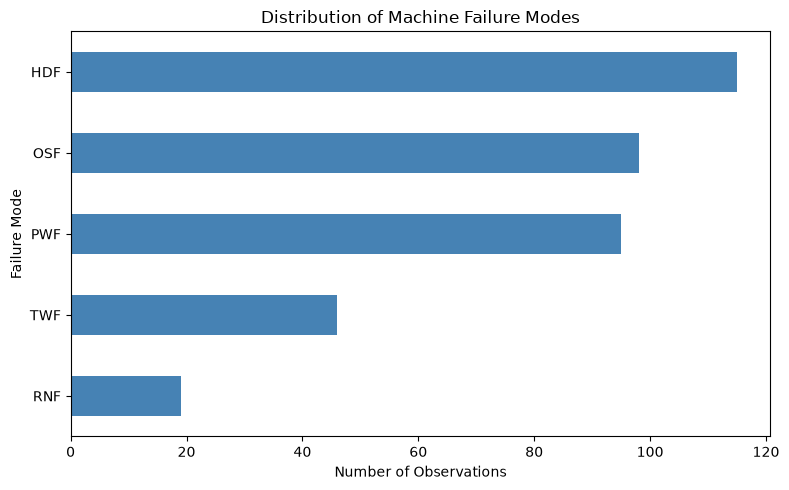

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

failure_counts.sort_values().plot(
    kind="barh",
    ax=ax,
    color="steelblue"
)

ax.set_title("Distribution of Machine Failure Modes")
ax.set_xlabel("Number of Observations")
ax.set_ylabel("Failure Mode")

plt.tight_layout()
plt.show()